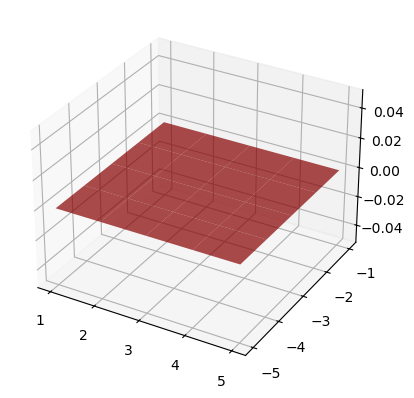

In [2]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
x_values = [1, 2, 3, 4, 5]
y_values = [1, 2, 3, 4, 5]
negative_y_values = [-1, -2, -3, -4, -5]
# Example: Plot a surface
X, Y = np.meshgrid(x_values, negative_y_values)
Z = np.zeros((len(negative_y_values), len(x_values)))
ax.plot_surface(X, Y, Z, color='r', alpha=0.7)

plt.show()

In [5]:
%gui qt
!pip3 install pyqt5
!pip3 install vtk
!pip3 install mayavi
!pip3 install pyqtgraph

  Obtaining dependency information for pyqtgraph from https://files.pythonhosted.org/packages/7b/34/5702b3b7cafe99be1d94b42f100e8cc5e6957b761fcb1cf5f72d492851da/pyqtgraph-0.13.7-py3-none-any.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 8.2 MB/s eta 0:00:0000:0100:01


In [ ]:
import vtk

# Create the points for the plane
points = vtk.vtkPoints()
points.InsertNextPoint(0, 0, 0)
points.InsertNextPoint(1, 0, 0)
points.InsertNextPoint(1, 1, 0)
points.InsertNextPoint(0, 1, 0)

# Create a polygon to represent the plane
polygon = vtk.vtkPolygon()
polygon.GetPointIds().SetNumberOfIds(4)
polygon.GetPointIds().SetId(0, 0)
polygon.GetPointIds().SetId(1, 1)
polygon.GetPointIds().SetId(2, 2)
polygon.GetPointIds().SetId(3, 3)

# Create a cell array to store the polygon
polygons = vtk.vtkCellArray()
polygons.InsertNextCell(polygon)

# Create a polydata to store everything in
polydata = vtk.vtkPolyData()
polydata.SetPoints(points)
polydata.SetPolys(polygons)

# Create a mapper and actor
mapper = vtk.vtkPolyDataMapper()
mapper.SetInputData(polydata)

actor = vtk.vtkActor()
actor.SetMapper(mapper)
actor.GetProperty().SetColor(0, 1, 0)  # Set the color to green

# and interactor
renderer = vtk.vtkRenderer()
render_window = vtk.vtkRenderWindow()
render_window.AddRenderer(renderer)
render_window_interactor = vtk.vtkRenderWindowInteractor()
render_window_interactor.SetRenderWindow(render_window)

# Add the actor to the scene
renderer.AddActor(actor)
renderer.SetBackground(1, 1, 1)  # Set background to white

# Render and start interaction
render_window.Render()
render_window_interactor.Start()

2025-02-19 21:00:06.063 python[6409:247493] +[IMKClient subclass]: chose IMKClient_Modern
2025-02-19 21:00:06.063 python[6409:247493] +[IMKInputSession subclass]: chose IMKInputSession_Modern


: 

In [1]:
import vtk

# Create a renderer
renderer = vtk.vtkRenderer()
renderer.SetBackground(1, 1, 1)  # Dark blue background

# Create a render window
render_window = vtk.vtkRenderWindow()
render_window.AddRenderer(renderer)
render_window.SetSize(800, 600)

# Create a render window interactor
interactor = vtk.vtkRenderWindowInteractor()
interactor.SetRenderWindow(render_window)

# Create axes
axes = vtk.vtkAxesActor()
axes.SetTotalLength(5, 5, 5)  # Set the length of the axes
axes.SetShaftTypeToCylinder()
axes.SetXAxisLabelText("X")
axes.SetYAxisLabelText("Y")
axes.SetZAxisLabelText("Z")

# Create the first plane (XY plane)
plane1 = vtk.vtkPlaneSource()
plane1.SetCenter(2, 2, 0)
plane1.SetNormal(0, 0, 1)
plane1.SetPoint1(4, 2, 0)
plane1.SetPoint2(2, 4, 0)

plane1Mapper = vtk.vtkPolyDataMapper()
plane1Mapper.SetInputConnection(plane1.GetOutputPort())

plane1Actor = vtk.vtkActor()
plane1Actor.SetMapper(plane1Mapper)
plane1Actor.GetProperty().SetColor(1, 0, 0)  # Red color
plane1Actor.GetProperty().SetOpacity(0.6)

# Create the second plane (XZ plane)
plane2 = vtk.vtkPlaneSource()
plane2.SetCenter(2, 0, 2)
plane2.SetNormal(0, 1, 0)
plane2.SetPoint1(4, 0, 2)
plane2.SetPoint2(2, 0, 4)

plane2Mapper = vtk.vtkPolyDataMapper()
plane2Mapper.SetInputConnection(plane2.GetOutputPort())

plane2Actor = vtk.vtkActor()
plane2Actor.SetMapper(plane2Mapper)
plane2Actor.GetProperty().SetColor(0, 1, 0)  # Green color
plane2Actor.GetProperty().SetOpacity(0.6)

# Add actors to renderer
renderer.AddActor(axes)
renderer.AddActor(plane1Actor)
renderer.AddActor(plane2Actor)

# Set up the camera
camera = renderer.GetActiveCamera()
camera.SetPosition(10, 10, 10)
camera.SetFocalPoint(0, 0, 0)
camera.SetViewUp(0, 0, 1)

# Initialize and start the interaction
interactor.Initialize()
render_window.Render()
interactor.Start()

: 

In [ ]:
import vtk
import numpy as np

# Create a renderer
renderer = vtk.vtkRenderer()
renderer.SetBackground(1, 1, 1)  # White background

# Create a render window
render_window = vtk.vtkRenderWindow()
render_window.AddRenderer(renderer)
render_window.SetSize(800, 600)

# Create a render window interactor
interactor = vtk.vtkRenderWindowInteractor()
interactor.SetRenderWindow(render_window)

# Create points for tick marks (0 through 5 for each axis)
points = vtk.vtkPoints()
labels = vtk.vtkStringArray()
labels.SetName("TickLabels")

# X axis ticks
for i in range(6):
    points.InsertNextPoint(i, 0, 0)
    labels.InsertNextValue(str(i))

# Y axis ticks
for i in range(6):
    points.InsertNextPoint(0, i, 0)
    labels.InsertNextValue(str(i))

# Z axis ticks
for i in range(6):
    points.InsertNextPoint(0, 0, i)
    labels.InsertNextValue(str(i))

# Create polydata for the points
point_data = vtk.vtkPolyData()
point_data.SetPoints(points)
point_data.GetPointData().AddArray(labels)

# Create labels for the points
label_mapper = vtk.vtkLabeledDataMapper()
label_mapper.SetInputData(point_data)
label_mapper.SetLabelModeToLabelFieldData()
label_mapper.SetFieldDataName("TickLabels")
label_mapper.GetLabelTextProperty().SetColor(0, 0, 0)  # Black color for labels
label_mapper.GetLabelTextProperty().SetFontSize(12)

label_actor = vtk.vtkActor2D()
label_actor.SetMapper(label_mapper)

# Create axes lines
axes = vtk.vtkAxesActor()
axes.SetTotalLength(5, 5, 5)
axes.SetShaftTypeToCylinder()
axes.SetXAxisLabelText("")  # Remove default labels
axes.SetYAxisLabelText("")
axes.SetZAxisLabelText("")

# Create grid lines for better visualization
grid = vtk.vtkRectilinearGrid()
x = np.linspace(0, 5, 6)
y = np.linspace(0, 5, 6)
z = np.linspace(0, 5, 6)

grid.SetDimensions(len(x), len(y), len(z))
xArray = vtk.vtkDoubleArray()
yArray = vtk.vtkDoubleArray()
zArray = vtk.vtkDoubleArray()

for i in x:
    xArray.InsertNextValue(i)
for i in y:
    yArray.InsertNextValue(i)
for i in z:
    zArray.InsertNextValue(i)

grid.SetXCoordinates(xArray)
grid.SetYCoordinates(yArray)
grid.SetZCoordinates(zArray)

# Create grid mapper and actor
grid_mapper = vtk.vtkDataSetMapper()
grid_mapper.SetInputData(grid)

grid_actor = vtk.vtkActor()
grid_actor.SetMapper(grid_mapper)
grid_actor.GetProperty().SetRepresentationToWireframe()
grid_actor.GetProperty().SetColor(0.7, 0.7, 0.7)  # Light gray color
grid_actor.GetProperty().SetOpacity(0.3)

# Create the first plane (XY plane)
plane1 = vtk.vtkPlaneSource()
plane1.SetCenter(2, 2, 0)
plane1.SetNormal(0, 0, 1)
plane1.SetPoint1(4, 2, 0)
plane1.SetPoint2(2, 4, 0)
plane1Mapper = vtk.vtkPolyDataMapper()
plane1Mapper.SetInputConnection(plane1.GetOutputPort())
plane1Actor = vtk.vtkActor()
plane1Actor.SetMapper(plane1Mapper)
plane1Actor.GetProperty().SetColor(1, 0, 0)  # Red color
plane1Actor.GetProperty().SetOpacity(0.6)

# Create the second plane (XZ plane)
plane2 = vtk.vtkPlaneSource()
plane2.SetCenter(2, 0, 2)
plane2.SetNormal(0, 1, 0)
plane2.SetPoint1(4, 0, 2)
plane2.SetPoint2(2, 0, 4)
plane2Mapper = vtk.vtkPolyDataMapper()
plane2Mapper.SetInputConnection(plane2.GetOutputPort())
plane2Actor = vtk.vtkActor()
plane2Actor.SetMapper(plane2Mapper)
plane2Actor.GetProperty().SetColor(0, 1, 0)  # Green color
plane2Actor.GetProperty().SetOpacity(0.6)

# Add all actors to renderer
renderer.AddActor(axes)
renderer.AddActor(grid_actor)
renderer.AddActor(label_actor)
renderer.AddActor(plane1Actor)
renderer.AddActor(plane2Actor)

# Set up the camera
camera = renderer.GetActiveCamera()
camera.SetPosition(10, 10, 10)
camera.SetFocalPoint(0, 0, 0)
camera.SetViewUp(0, 0, 1)

# Initialize and start the interaction
interactor.Initialize()
render_window.Render()
interactor.Start()

2025-02-20 15:33:07.004 python[11870:520475] +[IMKClient subclass]: chose IMKClient_Modern
2025-02-20 15:33:07.004 python[11870:520475] +[IMKInputSession subclass]: chose IMKInputSession_Modern


: 

In [1]:

# Define categorical labels for x-axis
x_category_labels = ['v_unp', 'unp', 'sl_unp', 'neutral', 'sl_imp', 'imp', 'v_imp']
x_values = [-60, -40, -20, 0, 20, 40, 60]

# Define y values and labels for negative and positive ranges
severity_map = {
    'severe': -50,
    'moderate': -25,
    'mild': -15,
    'no': 0
}

positive_values = [i * 3 for i in range(1, 21)]  # Positive values from 3 to 60

# Create separate y_values arrays for negative and positive methods
negative_y_values = list(severity_map.values())
positive_y_values = [0] + positive_values  # Include 0 for continuity
all_y_values = negative_y_values + positive_values[1:]  # Combined y-values for zero correlation methods

# Dictionary mapping preference levels to their respective dictionaries
preference_dicts = {
    'v_unp': (v_unp_dict, v_unp_dict_pos, v_unp_dict_zero),
    'unp': (unp_dict, unp_dict_pos, unp_dict_zero),
    'sl_unp': (sl_unp_dict, sl_unp_dict_pos, sl_unp_dict_zero),
    'neutral': (neutral_dict, neutral_dict_pos, neutral_dict_zero),
    'sl_imp': (sl_imp_dict, sl_imp_dict_pos, sl_imp_dict_zero),
    'imp': (imp_dict, imp_dict_pos, imp_dict_zero),
    'v_imp': (v_imp_dict, v_imp_dict_pos, v_imp_dict_zero)
}

# Methods classification
negative_only_methods = [
    "Hormonal IUD", "Patch", "Combination Pill"
]

positive_methods = [
    "Arm Implant", "Mini Pill", "Ring", "Shot"
]

zero_correlation_methods = [
    "Condoms", "Internal Condoms", "Cervical Cap", "FAM", 
    "Copper IUD", "Sterilization", "Spermicide", "Withdrawal"
]

# Create distinct color scale
distinct_colors = [
    [1.0, 0.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.84, 0.0], [1.0, 0.08, 0.58], [0.0, 1.0, 0.0], [0.55, 0.0, 0.55], [1.0, 0.55, 0.0],
    [0.0, 1.0, 1.0], [0.5, 0.0, 0.0], [0.0, 0.0, 0.5], [0.5, 0.5, 0.0], [1.0, 0.0, 1.0], [0.0, 0.5, 0.5], [1.0, 0.65, 0.0], [0.29, 0.0, 0.51]
]

# Function to create a surface plot
def create_surface_plot(x_values, y_values, z_values, color):
    points = vtk.vtkPoints()
    for i in range(len(x_values)):
        for j in range(len(y_values)):
            points.InsertNextPoint(x_values[i], y_values[j], z_values[j, i])

    poly_data = vtk.vtkPolyData()
    poly_data.SetPoints(points)

    delaunay = vtk.vtkDelaunay2D()
    delaunay.SetInputData(poly_data)
    delaunay.Update()

    mapper = vtk.vtkPolyDataMapper()
    mapper.SetInputConnection(delaunay.GetOutputPort())

    actor = vtk.vtkActor()
    actor.SetMapper(mapper)
    actor.GetProperty().SetColor(color)

    return actor

# Create the renderer, render window, and interactor
renderer = vtk.vtkRenderer()
render_window = vtk.vtkRenderWindow()
render_window.AddRenderer(renderer)
render_window_interactor = vtk.vtkRenderWindowInteractor()
render_window_interactor.SetRenderWindow(render_window)

# Process negative-only methods
for method_idx, method in enumerate(negative_only_methods):
    Z = np.zeros((len(negative_y_values), len(x_values)))
    
    for x_idx, x_label in enumerate(x_category_labels):
        neg_dict, _, _ = preference_dicts[x_label]
        
        for severity, y_pos in severity_map.items():
            y_idx = negative_y_values.index(y_pos)
            if severity in neg_dict and method in neg_dict[severity]:
                Z[y_idx, x_idx] = neg_dict[severity][method]
    
    actor = create_surface_plot(x_values, negative_y_values, Z, distinct_colors[method_idx])
    renderer.AddActor(actor)

# Process positive methods
for method_idx, method in enumerate(positive_methods, start=len(negative_only_methods)):
    Z = np.zeros((len(positive_y_values), len(x_values)))
    
    for x_idx, x_label in enumerate(x_category_labels):
        _, pos_dict, _ = preference_dicts[x_label]
        
        # Handle the 'no' case (y=0)
        y_idx = 0  # First index in positive_y_values (corresponds to 0)
        if 'no' in pos_dict and method in pos_dict['no']:
            Z[y_idx, x_idx] = pos_dict['no'][method]
        
        # Handle positive values
        for i, y_value in enumerate(positive_values, start=1):
            if str(y_value) in pos_dict and method in pos_dict[str(y_value)]:
                Z[i, x_idx] = pos_dict[str(y_value)][method]

    actor = create_surface_plot(x_values, positive_y_values, Z, distinct_colors[method_idx])
    renderer.AddActor(actor)

# Process zero correlation methods
for method_idx, method in enumerate(zero_correlation_methods, start=len(negative_only_methods) + len(positive_methods)):
    Z = np.zeros((len(all_y_values), len(x_values)))
    
    for x_idx, x_label in enumerate(x_category_labels):
        _, _, zero_dict = preference_dicts[x_label]
        
        # Handle negative severity values
        for severity, y_pos in severity_map.items():
            if y_pos in all_y_values:
                y_idx = all_y_values.index(y_pos)
                if severity in zero_dict and method in zero_dict[severity]:
                    Z[y_idx, x_idx] = zero_dict[severity][method]
        
        # Handle positive values
        for i, y_value in enumerate(positive_values):
            if y_value in all_y_values:
                y_idx = all_y_values.index(y_value)
                if str(y_value) in zero_dict and method in zero_dict[str(y_value)]:
                    Z[y_idx, x_idx] = zero_dict[str(y_value)][method]

    actor = create_surface_plot(x_values, all_y_values, Z, distinct_colors[method_idx])
    renderer.AddActor(actor)

# Set up the render window and interactor
renderer.SetBackground(1, 1, 1)  # Set background to white
render_window.SetSize(1200, 800)
render_window.Render()
render_window_interactor.Start()

NameError: name 'v_unp_dict' is not defined